<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab4/lab4_2_classification_sentiment_topics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4.2 – Document classification, sentiment analysis and topic modeling

**Objectives**
- Train and evaluate document classifiers on news and on legal decisions
- Build sentiment classifiers for product reviews and for tweets
- Discover topics in research abstracts (LDA) and in legal contracts (NMF)
- Choose feature extraction methods according to the kind of text

| Task | Introductory use case | Advanced use case |
|------|-----------------------|-------------------|
| Classification | AG News (news topics) | ECtHR court decisions (LexGLUE) |
| Sentiment analysis | Amazon product reviews | Tweets (TweetEval) |
| Topic modeling | arXiv abstracts (live arXiv API) | Legal contracts |

All datasets are public. The notebook downloads them from Hugging Face or from the arXiv API, and falls back to local samples shipped with the lab (`data/`) when a download fails.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, json, time, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.decomposition import LatentDirichletAllocation, NMF

from datasets import load_dataset

def local_file(name, lab="lab4"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

def load_or_fallback(loader, fallback_name):
    """Run loader() (network); on failure read the local sample. Returns (train_df, test_df)."""
    try:
        train_df, test_df = loader()
        print("Loaded from the network")
    except Exception as e:
        print(f"Network source unavailable ({type(e).__name__}: {str(e)[:80]}), using the local sample")
        df = pd.read_csv(local_file(fallback_name))
        train_df, test_df = df[df["split"] == "train"].drop(columns="split"), df[df["split"] == "test"].drop(columns="split")
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

print("Setup complete")

Setup complete


In [3]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_simple(text):
    """Lowercase, letters only, single spaces."""
    text = re.sub(r"[^a-zA-Z\s]", " ", str(text).lower())
    return " ".join(text.split())

def preprocess_advanced(text):
    """preprocess_simple + stop word removal + lemmatization + words of 3+ characters."""
    tokens = word_tokenize(preprocess_simple(text))
    return " ".join(lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2)

print(preprocess_advanced("The researchers at MIT have published 5 new papers!"))

researcher mit published new paper


---
# Part A – Document classification

## A.1 News topics (AG News)

**Scenario:** a media company routes incoming articles to its editorial teams (World, Sports, Business, Sci/Tech).

In [4]:
def load_ag_news():
    ds = load_dataset("fancyzhx/ag_news")
    return (pd.DataFrame(ds["train"]).sample(n=8000, random_state=42),
            pd.DataFrame(ds["test"]).sample(n=2000, random_state=42))

ag_train, ag_test = load_or_fallback(load_ag_news, "ag_news_sample.csv.gz")
ag_labels = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
print(f"Train: {len(ag_train)}, test: {len(ag_test)}")
print(ag_train["label"].map(ag_labels).value_counts())
ag_train.head(3)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Loaded from the network
Train: 8000, test: 2000
label
Sports      2074
Sci/Tech    2021
Business    1959
World       1946
Name: count, dtype: int64


,text,label
0,"BBC set for major shake-up, claims newspaper L...",2
1,Marsh averts cash crunch Embattled insurance b...,2
2,"Jeter, Yankees Look to Take Control (AP) AP - ...",1


### Exercise A.1 – TF-IDF + logistic regression

In [5]:
ag_train["text_clean"] = ag_train["text"].apply(preprocess_simple)
ag_test["text_clean"] = ag_test["text"].apply(preprocess_simple)
y_train_ag, y_test_ag = ag_train["label"], ag_test["label"]

tfidf_ag = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)     # YOUR CODE HERE: TfidfVectorizer (choose max_features, ngram_range, min_df)
X_train_ag = tfidf_ag.fit_transform(ag_train["text_clean"])   # YOUR CODE HERE: fit_transform on the train texts
X_test_ag = tfidf_ag.transform(ag_test["text_clean"])    # YOUR CODE HERE: transform the test texts

clf_ag = LogisticRegression(max_iter=1000)
clf_ag.fit(X_train_ag, y_train_ag)      # YOUR CODE HERE: LogisticRegression(max_iter=1000), then fit
y_pred_ag = y_pred_ag = clf_ag.predict(X_test_ag)    # YOUR CODE HERE: predictions on X_test_ag


accuracy_ag = accuracy_score(y_test_ag, y_pred_ag)
f1_ag = f1_score(y_test_ag, y_pred_ag, average="macro")
print(f"AG News – accuracy: {accuracy_ag:.4f}, F1 macro: {f1_ag:.4f}\n")
print(classification_report(y_test_ag, y_pred_ag, target_names=list(ag_labels.values())))
assert accuracy_ag > 0.80, "A TF-IDF + logistic regression model should exceed 80% accuracy"

AG News – accuracy: 0.8735, F1 macro: 0.8726

              precision    recall  f1-score   support

       World       0.90      0.87      0.88       493
      Sports       0.92      0.95      0.93       504
    Business       0.83      0.81      0.82       474
    Sci/Tech       0.85      0.86      0.85       529

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



## A.2 Court decisions (LexGLUE – ECtHR)

**Scenario:** a law firm classifies decisions of the European Court of Human Rights by the article of the Convention that was violated.

**Challenge:** long documents, specialized vocabulary, many labels. Documents are lists of paragraphs; they are joined and truncated to 5 000 characters, and only the first label of each decision is kept (single-label simplification).

In [6]:
def load_ecthr():
    ds = load_dataset("coastalcph/lex_glue", "ecthr_a")
    def prep(split, n):
        df = pd.DataFrame(ds[split]).sample(n=min(n, len(ds[split])), random_state=42)
        df["text"] = df["text"].apply(lambda paras: " ".join(paras)[:5000])
        df["labels"] = df["labels"].apply(lambda l: json.dumps([int(x) for x in l]))
        return df[["text", "labels"]]
    return prep("validation", 1000), prep("test", 500)     # validation split used for training (smaller download)

lex_train, lex_test = load_or_fallback(load_ecthr, "ecthr_a_sample.csv.gz")
for df in (lex_train, lex_test):
    df["primary_label"] = df["labels"].apply(lambda s: json.loads(s)[0] if json.loads(s) else -1)
lex_train = lex_train[lex_train["primary_label"] >= 0].reset_index(drop=True)
lex_test = lex_test[lex_test["primary_label"] >= 0].reset_index(drop=True)

print(f"Train: {len(lex_train)}, test: {len(lex_test)} (decisions without violated article removed)")
print("Label distribution (train):"); print(lex_train["primary_label"].value_counts().head(8))
print("\n" + lex_train.iloc[0]["text"][:500])

README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

ecthr_a/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 42.4MB            

ecthr_a/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ecthr_a/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.68MB            

ecthr_a/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ecthr_a/validation-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.26MB            

ecthr_a/validation-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loaded from the network
Train: 825, test: 428 (decisions without violated article removed)
Label distribution (train):
primary_label
3    249
1    178
2    116
9     75
4     58
0     56
6     42
7     33
Name: count, dtype: int64

4.  The applicant was born in 1967 and lives in Chișinău. 5.  On 2 October 2008 the Chișinău Court of Appeal delivered a judgment acknowledging the applicant’s entitlement to a disability pension. Owing to the lack of an appeal, the judgment became final on 22 October 2008. 6.  On 1 December 2008 the Ministry of Defence lodged an appeal on points of law. 7.  On 4 February 2009 the Supreme Court of Justice allowed the appeal on points of law, quashed the judgment of 2 October 2008 and remitted th


### Exercise A.2 – Bag of words with n-grams + linear SVM

In [8]:
lex_train["text_clean"] = lex_train["text"].apply(preprocess_advanced)
lex_test["text_clean"] = lex_test["text"].apply(preprocess_advanced)
y_train_lex, y_test_lex = lex_train["primary_label"], lex_test["primary_label"]

bow_legal = CountVectorizer(
    max_features=5000,   # YOUR CODE HERE: 3000-5000
    ngram_range=(1, 2),    # YOUR CODE HERE: (1, 1), (1, 2) or (1, 3)
    min_df=2,         # YOUR CODE HERE: 2-5
    max_df=0.95,         # YOUR CODE HERE: 0.9-0.99
)
X_train_lex = bow_legal.fit_transform(lex_train["text_clean"])   # YOUR CODE HERE
X_test_lex = bow_legal.transform(lex_test["text_clean"])    # YOUR CODE HERE

clf_legal = LinearSVC(max_iter=5000)
clf_legal.fit(X_train_lex, y_train_lex)     # YOUR CODE HERE: LinearSVC (or another linear model), then fit
y_pred_lex = clf_legal.predict(X_test_lex)    # YOUR CODE HERE


accuracy_lex = accuracy_score(y_test_lex, y_pred_lex)
f1_lex = f1_score(y_test_lex, y_pred_lex, average="macro")
print(f"ECtHR – accuracy: {accuracy_lex:.4f}, F1 macro: {f1_lex:.4f}")
assert X_train_lex.shape[1] <= 5000 and accuracy_lex > 0.4, "Check the vectorizer and the classifier"

ECtHR – accuracy: 0.6682, F1 macro: 0.5088


### Question A.3 (written)

1. Which task reached the higher accuracy? Why?
2. Which vectorizer parameters did you choose for the legal texts? Justify each one.
3. What makes legal document classification harder? (length, vocabulary, label ambiguity, multi-label nature...)

<!-- ANSWER lab4.2-A3 -->
1. AG News reached the higher accuracy, probably because news have clearer topics and more distinctive vocabulary. AG News als reached a higher macro score, which shows more balanced performance.

2.
max_features=5000: Limits vocabulary size
ngram_range=(1,2): Captures individual words and legal phrases
min_df=2: Removes very rare words
max_df=0.95: Removes extremely common words

3.They are longer, use special vocabulary, share similar terminology and can fit multible labels, which makes classification harder.
<!-- END ANSWER -->

---
# Part B – Sentiment analysis

## B.1 Product reviews (Amazon)

**Scenario:** an e-commerce company monitors the sentiment of customer reviews. The dataset is the English part of *Amazon Reviews Multi* (star ratings from 1 to 5).

In [9]:
def load_amazon():
    base = "hf://datasets/SetFit/amazon_reviews_multi_en/"
    tr = pd.read_json(base + "train.jsonl", lines=True).sample(n=5000, random_state=42)
    te = pd.read_json(base + "test.jsonl", lines=True).sample(n=1000, random_state=42)
    return tr[["text", "label"]], te[["text", "label"]]

amazon_train, amazon_test = load_or_fallback(load_amazon, "amazon_reviews_sample.csv.gz")
for df in (amazon_train, amazon_test):
    df["stars"] = df["label"] + 1                      # label 0..4 -> 1..5 stars
    df["sentiment"] = df["stars"].map({1: 0, 2: 0, 3: -1, 4: 1, 5: 1})   # -1 = neutral, removed below
amazon_train = amazon_train[amazon_train["sentiment"] >= 0].reset_index(drop=True)
amazon_test = amazon_test[amazon_test["sentiment"] >= 0].reset_index(drop=True)

print(f"Train: {len(amazon_train)}, test: {len(amazon_test)} (3-star reviews removed)")
print(amazon_train["sentiment"].value_counts().rename({0: "negative", 1: "positive"}))
print("\nPositive:", amazon_train[amazon_train["sentiment"] == 1].iloc[0]["text"][:200])
print("Negative:", amazon_train[amazon_train["sentiment"] == 0].iloc[0]["text"][:200])

Loaded from the network
Train: 3997, test: 808 (3-star reviews removed)
sentiment
positive    2008
negative    1989
Name: count, dtype: int64

Positive: Really cute mug. I would have given 5 stars if it were a bit bigger.
Negative: The leg openings are a little small, but other than that the suit fits nicely, and is high quality material. Edit: I have been wearing this for less than two months and it is 100% worn out. It has wor


### Exercise B.1 – TF-IDF + Naive Bayes

In [10]:
amazon_train["text_clean"] = amazon_train["text"].apply(preprocess_simple)
amazon_test["text_clean"] = amazon_test["text"].apply(preprocess_simple)
y_train_amz, y_test_amz = amazon_train["sentiment"], amazon_test["sentiment"]

tfidf_amazon = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)   # YOUR CODE HERE
X_train_amz = tfidf_amazon.fit_transform(amazon_train["text_clean"])    # YOUR CODE HERE
X_test_amz = tfidf_amazon.transform(amazon_test["text_clean"])     # YOUR CODE HERE

clf_amazon = MultinomialNB()
clf_amazon.fit(X_train_amz, y_train_amz)     # YOUR CODE HERE: MultinomialNB (or another model), then fit
y_pred_amz = clf_amazon.predict(X_test_amz)     # YOUR CODE HERE

f1_amz = f1_score(y_test_amz, y_pred_amz, average="macro")
print(f"Amazon – accuracy: {accuracy_score(y_test_amz, y_pred_amz):.4f}, F1 macro: {f1_amz:.4f}\n")
print(classification_report(y_test_amz, y_pred_amz, target_names=["negative", "positive"]))
assert f1_amz > 0.75, "Expected an F1 above 0.75 on this binary task"

Amazon – accuracy: 0.8552, F1 macro: 0.8552

              precision    recall  f1-score   support

    negative       0.85      0.86      0.86       406
    positive       0.86      0.85      0.85       402

    accuracy                           0.86       808
   macro avg       0.86      0.86      0.86       808
weighted avg       0.86      0.86      0.86       808



In [11]:
# Most indicative words (works for MultinomialNB and for linear models)
feature_names = tfidf_amazon.get_feature_names_out()
if hasattr(clf_amazon, "feature_log_prob_"):
    weights = clf_amazon.feature_log_prob_[1] - clf_amazon.feature_log_prob_[0]
elif hasattr(clf_amazon, "coef_"):
    weights = clf_amazon.coef_[0]
else:
    weights = None
if weights is not None:
    order = weights.argsort()
    print("Most POSITIVE words:", list(feature_names[order[-15:]][::-1]))
    print("Most NEGATIVE words:", list(feature_names[order[:15]]))

Most POSITIVE words: ['loves', 'love', 'perfect for', 'perfect', 'exactly', 'very nice', 'love it', 'works great', 'amazing', 'excellent', 'love this', 'easy to', 'comfortable', 'works', 'exactly what']
Most NEGATIVE words: ['never received', 'waste', 'never', 'poor', 'return', 'waste of', 'broken', 'stopped working', 'returned', 'disappointed', 'not work', 'very disappointed', 'broke', 'waste your', 'stopped']


## B.2 Tweets (TweetEval)

**Scenario:** a brand monitors what people say about it on social media. Three classes: negative, neutral, positive.

**Challenge:** short and informal texts, hashtags, mentions, slang and misspellings. Character n-grams are robust to these variations.

In [12]:
def load_tweets():
    ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
    return pd.DataFrame(ds["train"]), pd.DataFrame(ds["test"])

tweet_train, tweet_test = load_or_fallback(load_tweets, "tweet_eval_sentiment.csv.gz")
tweet_labels = {0: "negative", 1: "neutral", 2: "positive"}
print(f"Train: {len(tweet_train)}, test: {len(tweet_test)}")
print(tweet_train["label"].map(tweet_labels).value_counts())
for label in [0, 1, 2]:
    print(f"\n[{tweet_labels[label]}] {tweet_train[tweet_train['label'] == label].iloc[0]['text']}")

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loaded from the network
Train: 45615, test: 12284
label
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64

[negative] So disappointed in wwe summerslam! I want to see john cena wins his 16th title

[neutral] "Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ"

[positive] "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"


In [13]:
def preprocess_tweet(text):
    """Lowercase; replace mentions by @user and URLs by URL; keep letters, @ and #."""
    text = str(text).lower()
    text = re.sub(r"@\w+", "@user", text)
    text = re.sub(r"http\S+", "URL", text)
    text = re.sub(r"[^a-zA-Z@#\s]", "", text)
    return " ".join(text.split())

tweet_train["text_clean"] = tweet_train["text"].apply(preprocess_tweet)
tweet_test["text_clean"] = tweet_test["text"].apply(preprocess_tweet)
print(tweet_train.iloc[0]["text"], "\n->", tweet_train.iloc[0]["text_clean"])

"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 
-> qt @user in the original draft of the th book remus lupin survived the battle of hogwarts #happybirthdayremuslupin


### Exercise B.2 – Character n-grams + logistic regression

Tweets – accuracy: 0.5891, F1 macro: 0.5608

              precision    recall  f1-score   support

    negative       0.67      0.36      0.47      3972
     neutral       0.60      0.73      0.66      5937
    positive       0.50      0.61      0.55      2375

    accuracy                           0.59     12284
   macro avg       0.59      0.57      0.56     12284
weighted avg       0.60      0.59      0.58     12284



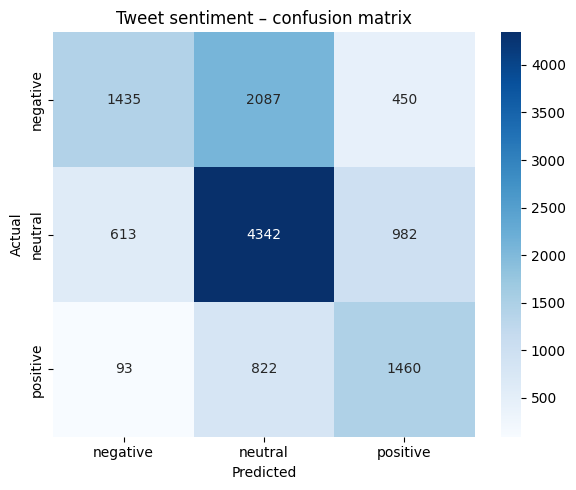

In [15]:
y_train_tw, y_test_tw = tweet_train["label"], tweet_test["label"]

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",       # YOUR CODE HERE: "char_wb" = character n-grams inside word boundaries
    ngram_range=(2,5),    # YOUR CODE HERE: (2, 5) or (3, 6)
    max_features=5000,   # YOUR CODE HERE: 3000-5000
    min_df=2,         # YOUR CODE HERE: 2-5
)
X_train_tw = char_vectorizer.fit_transform(tweet_train["text"])    # YOUR CODE HERE
X_test_tw = char_vectorizer.transform(tweet_test["text"])     # YOUR CODE HERE

clf_tweet = LogisticRegression(max_iter=1000)
clf_tweet.fit(X_train_tw, y_train_tw)     # YOUR CODE HERE: LogisticRegression(max_iter=1000), then fit
y_pred_tw = clf_tweet.predict(X_test_tw)     # YOUR CODE HERE

f1_tw = f1_score(y_test_tw, y_pred_tw, average="macro")
print(f"Tweets – accuracy: {accuracy_score(y_test_tw, y_pred_tw):.4f}, F1 macro: {f1_tw:.4f}\n")
print(classification_report(y_test_tw, y_pred_tw, target_names=list(tweet_labels.values())))
assert f1_tw > 0.5, "Expected a macro F1 above 0.5 on the 3 classes"

cm = confusion_matrix(y_test_tw, y_pred_tw)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=tweet_labels.values(), yticklabels=tweet_labels.values())
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Tweet sentiment – confusion matrix")
plt.tight_layout(); plt.show()

### Question B.3 (written)

1. Which task was harder, Amazon reviews or tweets? Compare the F1 scores and explain.
2. Why character n-grams for tweets? What do they bring compared with word n-grams?
3. Which class is confused most often in the confusion matrix? Why?
4. Write one tweet that would be hard to classify and explain why.

<!-- ANSWER lab4.2-B3 -->

1. Tweets were harder to classify, likly because amazon reviews are clearer, while tweets contain sarcasm and less context. also amazon has only two classes while tweets has three.
2. Character n-grams can recognize informal language.
3. neg. tweets are most often misclassified, becuase they may contain sarcasm or ambigious language.
4. [positive] "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"
   difficult to classify, because it suggest pos sentiment, unless you know the character is dead.
<!-- END ANSWER -->

---
# Part C – Topic modeling

## C.1 Research abstracts (arXiv) with LDA

**Scenario:** a research organization wants an overview of the themes in recent papers. Abstracts are fetched from the public arXiv API (6 categories, 300 recent papers each). The true arXiv category is kept to check the topics afterwards.

In [16]:
import xml.etree.ElementTree as ET
import requests

ARXIV_CATEGORIES = ["cs.CL", "cs.CV", "cs.CR", "q-bio.GN", "econ.GN", "astro-ph.GA"]

def fetch_arxiv(categories=ARXIV_CATEGORIES, per_category=300):
    """Recent abstracts per category from the arXiv API (about 3 seconds per category)."""
    ns, rows = {"a": "http://www.w3.org/2005/Atom"}, []
    for cat in categories:
        r = requests.get("https://export.arxiv.org/api/query", timeout=120,
                         params={"search_query": f"cat:{cat}", "start": 0, "max_results": per_category,
                                 "sortBy": "submittedDate", "sortOrder": "descending"})
        r.raise_for_status()
        for e in ET.fromstring(r.content).findall("a:entry", ns):
            rows.append({"category": cat, "title": " ".join(e.find("a:title", ns).text.split()),
                         "abstract": " ".join(e.find("a:summary", ns).text.split())})
        time.sleep(3)   # arXiv asks for a delay between requests
    df = pd.DataFrame(rows)
    assert len(df) > 100
    return df, df.iloc[:0]

arxiv_df, _ = load_or_fallback(fetch_arxiv, "arxiv_abstracts_sample.csv.gz")
print(f"{len(arxiv_df)} abstracts")
print(arxiv_df["category"].value_counts())
print("\n" + arxiv_df.iloc[0]["title"] + "\n" + arxiv_df.iloc[0]["abstract"][:400])

Loaded from the network
1800 abstracts
category
cs.CL          300
cs.CV          300
cs.CR          300
q-bio.GN       300
econ.GN        300
astro-ph.GA    300
Name: count, dtype: int64

CodeQuant2: Enhanced Outlier Mitigation and Adaptive Clustering for Low-Precision LRMs
Large reasoning models (LRMs) improve task performance by generating longer intermediate reasoning traces, but this substantially increases inference costs and makes low-precision quantization increasingly important. However, aggressively quantized models often perform poorly on reasoning tasks. We observe larger activation fluctuations during the first decoding steps of reasoning. Calibration tha


### Exercise C.1 – LDA on the abstracts

In [17]:
arxiv_df["abstract_clean"] = arxiv_df["abstract"].apply(preprocess_advanced)

count_vec_arxiv = CountVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.95
)   # YOUR CODE HERE: CountVectorizer (max_features, min_df, max_df)
n_topics_arxiv = 9    # YOUR CODE HERE: 6-12 topics

dtm_arxiv = count_vec_arxiv.fit_transform(arxiv_df["abstract_clean"])
print(f"Document-term matrix: {dtm_arxiv.shape}")

lda_arxiv = LatentDirichletAllocation(n_components=n_topics_arxiv, random_state=42, max_iter=20, learning_method="online")
lda_arxiv.fit(dtm_arxiv)

def show_topics(model, feature_names, n_words=12):
    for i, topic in enumerate(model.components_):
        print(f"Topic {i}: " + ", ".join(feature_names[j] for j in topic.argsort()[::-1][:n_words]))

show_topics(lda_arxiv, count_vec_arxiv.get_feature_names_out())

Document-term matrix: (1800, 4878)
Topic 0: galaxy, star, mass, formation, stellar, sim, using, density, cluster, population, field, matter
Topic 1: model, image, based, method, across, framework, task, data, language, performance, benchmark, representation
Topic 2: disk, spiral, metallicity, bulge, abundance, passage, last, solar, expert, arm, sfh, carbon
Topic 3: model, reasoning, training, policy, student, reward, teacher, response, across, preference, generation, bar
Topic 4: cell, gene, single, expression, genome, biological, type, sequence, rna, dna, regulatory, across
Topic 5: data, model, analysis, across, study, evidence, clinical, patient, classification, level, genomic, cohort
Topic 6: agent, attack, model, system, market, across, price, data, cost, tool, task, human
Topic 7: model, one, two, per, time, every, token, fixed, point, three, test, error
Topic 8: galaxy, dust, gas, jwst, agn, stellar, sfhs, emission, mass, attenuation, bright, model


### Exercise C.2 – Name the topics and compare with the real categories

In [19]:
# Give a short label to each topic from its top words
my_arxiv_topic_labels = {
    0: "Galaxy and Star Formation",
    1: "AI and Machine Learning",
    2: "Stellar Structure and Chemistry",
    3: "AI Reasoning and Training",
    4: "Genetics and Genomics",
    5: "Medical and Clinical Research",
    6: "AI Agents and Security",
    7: "Mathematical and Model Analysis",
    8: "Galaxies and Astrophysics"
 } #{i: "___" for i in range(n_topics_arxiv)}   # YOUR CODE HERE: replace each "___"
assert all(v != "9" for v in my_arxiv_topic_labels.values()), "Label every topic"



arxiv_df["dominant_topic"] = lda_arxiv.transform(dtm_arxiv).argmax(axis=1)
crosstab = pd.crosstab(arxiv_df["category"], arxiv_df["dominant_topic"].map(my_arxiv_topic_labels))
crosstab

dominant_topic,AI Agents and Security,AI Reasoning and Training,AI and Machine Learning,Galaxies and Astrophysics,Galaxy and Star Formation,Genetics and Genomics,Mathematical and Model Analysis,Medical and Clinical Research,Stellar Structure and Chemistry
category,,,,,,,,,
astro-ph.GA,0,0,6,4,283,0,7,0,0
cs.CL,39,19,126,0,0,0,102,13,1
cs.CR,111,0,103,0,0,0,83,3,0
cs.CV,5,5,240,0,0,0,42,8,0
econ.GN,223,2,18,0,1,0,52,4,0
q-bio.GN,8,0,170,0,0,33,56,33,0


## C.2 Legal contracts with NMF

**Scenario:** a law firm organizes its contract database by theme (employment, confidentiality, licensing, services...). NMF on TF-IDF vectors often gives cleaner topics than LDA on specialized corpora.

In [20]:
import fsspec, pyarrow.parquet as pq

def load_legal_contracts(n=1000, max_chars=8000):
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"
    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")
    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))
    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]
    return df.reset_index(drop=True)

legal_df = load_legal_contracts(n=1000)
legal_df["text_clean"] = legal_df["text"].apply(preprocess_advanced)
print(f"{len(legal_df)} contracts")
print(legal_df.iloc[0]["text_clean"][:300])

Loaded from Hugging Face
1000 contracts
quicklinks click rapidly navigate document amended restated employment noncompetition agreement amended restated employment noncompetition agreement agreement made entered october among avocent employment service formerly known polycon investment inc texas corporation employer avocent corporation de


### Exercise C.3 – NMF on TF-IDF vectors

Topic 0: executive, company, shall, employment, benefit, agreement, salary, termination, base, date, bonus, term
Topic 1: borrower, loan, credit, lender, bank, agreement, agent, amendment, section, administrative, revolving, amended
Topic 2: option, plan, stock, share, participant, committee, award, shall, mean, common, section, granted
Topic 3: employee, employment, company, agreement, shall, termination, bonus, employer, salary, benefit, year, term
Topic 4: agreement, seller, buyer, purchase, shall, party, product, point, purchaser, natural, gas, amendment
Topic 5: company, voting, security, director, control, change, outstanding, board, corporation, person, combination, election
Topic 6: note, maker, principal, interest, shall, holder, due, promissory, default, amount, payment, unpaid
Topic 7: tenant, landlord, lease, premise, rent, building, lessee, lessor, section, shall, improvement, area


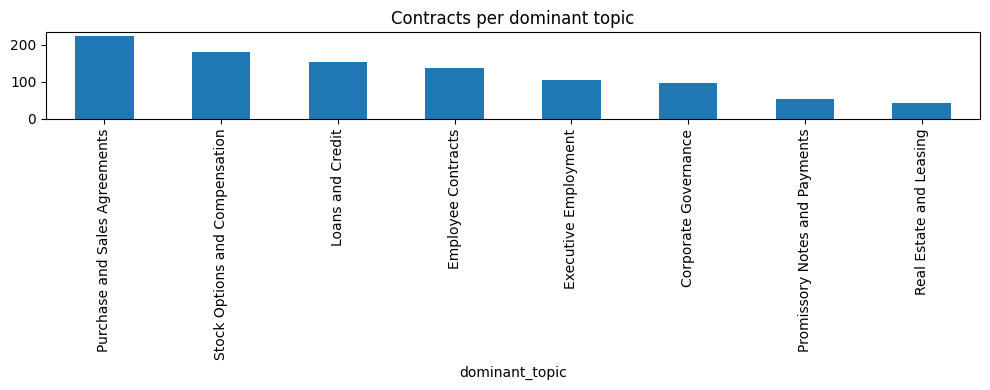

In [23]:
tfidf_legal = TfidfVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.95
)      # YOUR CODE HERE: TfidfVectorizer (max_features, min_df, max_df)
n_topics_legal = 8   # YOUR CODE HERE: 5-12 topics

dtm_legal = tfidf_legal.fit_transform(legal_df["text_clean"])
nmf_legal = NMF(n_components=n_topics_legal, random_state=42, max_iter=300)
nmf_legal.fit(dtm_legal)
show_topics(nmf_legal, tfidf_legal.get_feature_names_out())

my_legal_topic_labels = {
    0: "Executive Employment",
    1: "Loans and Credit",
    2: "Stock Options and Compensation",
    3: "Employee Contracts",
    4: "Purchase and Sales Agreements",
    5: "Corporate Governance",
    6: "Promissory Notes and Payments",
    7: "Real Estate and Leasing"
} #{i: "" for i in range(n_topics_legal)}   # YOUR CODE HERE
assert all(v != "" for v in my_legal_topic_labels.values()), "Label every topic"

legal_df["dominant_topic"] = nmf_legal.transform(dtm_legal).argmax(axis=1)
counts = legal_df["dominant_topic"].map(my_legal_topic_labels).value_counts()
counts.plot(kind="bar", figsize=(10, 4), title="Contracts per dominant topic")
plt.tight_layout(); plt.show()

### Question C.4 (written)

1. Which topics were easier to interpret, arXiv (LDA) or contracts (NMF)? Why?
2. Looking at the cross-table of Exercise C.2: do the LDA topics match the real arXiv categories? Which categories get mixed?
3. Is the distribution of contracts across topics balanced? What does it tell about the corpus?
4. For each corpus, propose 2 topics to merge and 1 topic to split, with a justification.

<!-- ANSWER lab4.2-C4 -->
1. Contracts, because they contains clear vocabulary. Some arXiv topics have mixed vocab from different scientific fields.
2. Partially. Some categories overlap.
3. No, its unbalanced. Purchase and sales is the lagest, while real estate has the fewest. This suggest it contains more financial agrements thean real estate.
4. - arXiv 0 and 8 focus on astonomy
   - arXiv 6 mixes cybersecurity and economics
   - contracts 0 and 3 are both about employee agreements
   - contracts 4 is about different types of purchase agreements
<!-- END ANSWER -->

---
## Summary

| Task | Dataset | Features | Model |
|------|---------|----------|-------|
| Classification | AG News | TF-IDF | Logistic regression |
| Classification | ECtHR decisions | Bag of words + n-grams | Linear SVM |
| Sentiment | Amazon reviews | TF-IDF | Naive Bayes |
| Sentiment | Tweets | Character n-grams | Logistic regression |
| Topic modeling | arXiv abstracts | Word counts | LDA |
| Topic modeling | Legal contracts | TF-IDF | NMF |

- Short, clean, balanced texts are easy; long, specialized or noisy texts need adapted features.
- Character n-grams are robust to the noise of social media text.
- LDA and NMF both produce "topics" as word lists; checking them against known categories is the best way to judge them.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.